# Original Implementation

---

In [1]:
#=========
# Imports
#=========

import time
import csv
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [4]:
#=================================
# Configuration & Reproducibility
#=================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Training configuration
EPOCHS = 400
LEARNING_RATE = 0.01
BATCH_SIZE = 32  # Defined by the author, but not used in training.

# Dataset configuration
TEST_SIZE = 0.2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
#=============
# Data Loading
#=============

def load_csv(filename):
    lines = []

    with open(filename) as csvfile:
        reader = csv.DictReader(csvfile)

        for line in reader:
            lines.append(line)

    return lines

In [6]:
#=============
# Load Dataset
#=============

DATA_PATH = "data/healthcare-dataset-stroke-data.csv"

data = load_csv(DATA_PATH)

In [7]:
#================
# Data Inspection
#=================

print(f"Number of records: {len(data)}")
print(f"Number of features: {len(data[0])}")

print("\nColumn names:")
print(list(data[0].keys()))

print("\nFirst record:")
print(data[0])

Number of records: 5110
Number of features: 12

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

First record:
{'id': '9046', 'gender': 'Male', 'age': '67', 'hypertension': '0', 'heart_disease': '1', 'ever_married': 'Yes', 'work_type': 'Private', 'Residence_type': 'Urban', 'avg_glucose_level': '228.69', 'bmi': '36.6', 'smoking_status': 'formerly smoked', 'stroke': '1'}


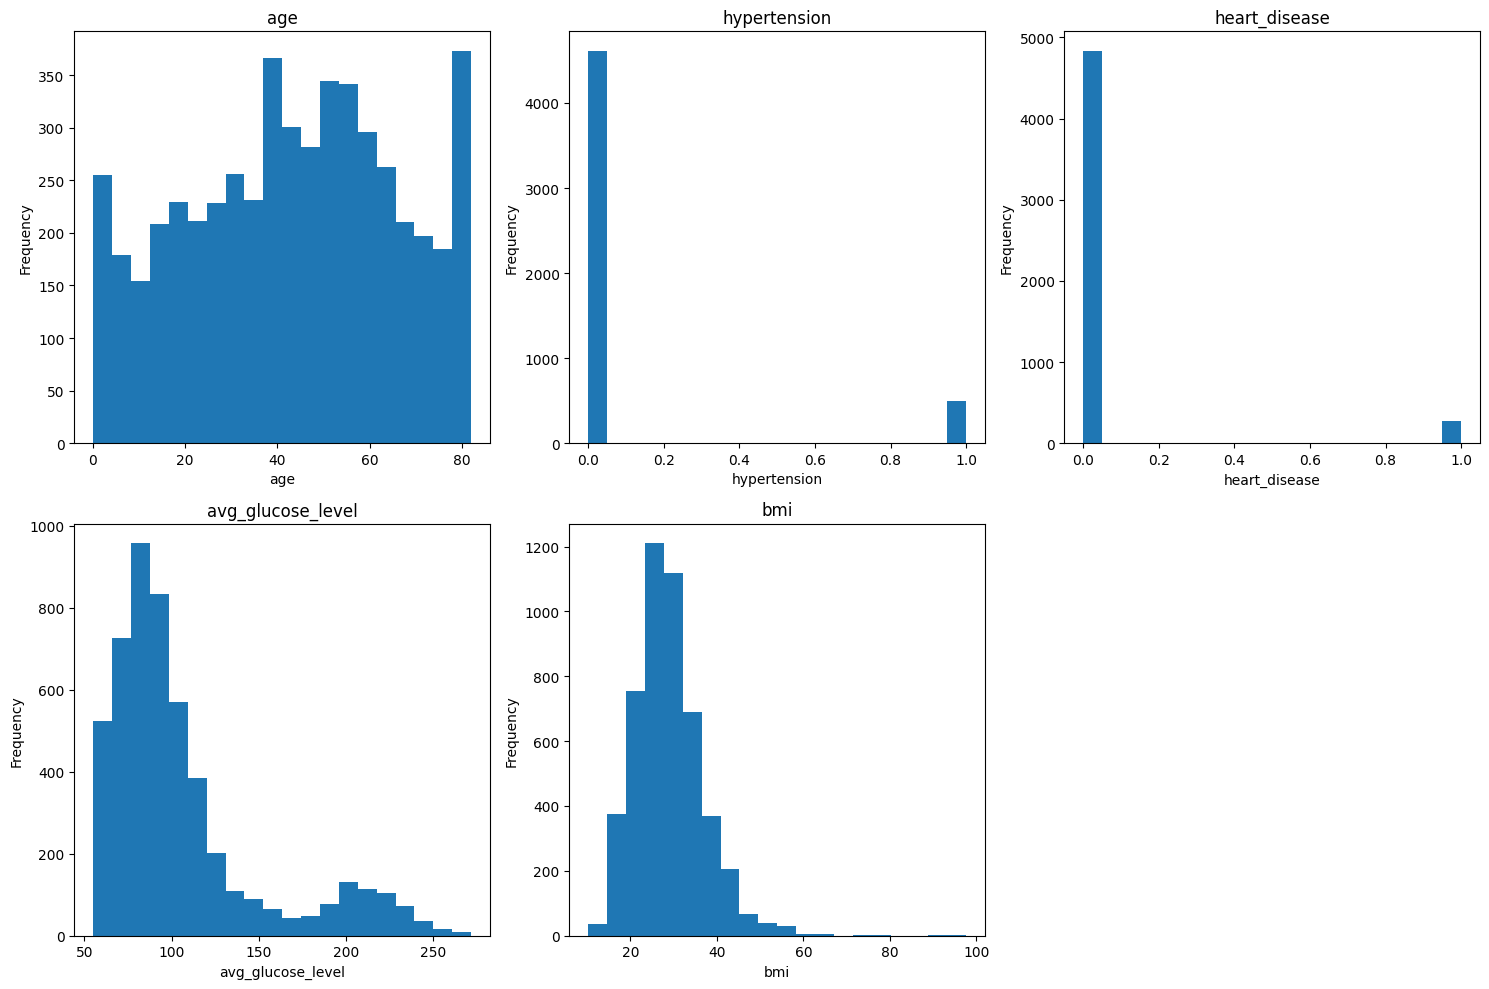

In [8]:
#==========================
# Exploratory Data Analysis
#==========================

numerical_features = [
    key for key in data[0].keys()
    if key not in [
        'id',
        'gender',
        'ever_married',
        'work_type',
        'Residence_type',
        'smoking_status',
        'stroke'
    ]
]

num_plots = len(numerical_features)
num_cols = 3
num_rows = (num_plots + num_cols - 1) // num_cols

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(15, 5 * num_rows)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    try:
        values = [
            float(item[feature])
            for item in data
            if item[feature] != 'N/A'
        ]

        axes[i].hist(values, bins=20)
        axes[i].set_title(feature)
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel("Frequency")

    except (ValueError, TypeError):
        print(f"Skipping {feature} due to non-numeric or invalid values")

    except IndexError:
        pass

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [9]:
#===================
# Data Preprocessing
#===================

df = pd.read_csv(DATA_PATH)

# Handle missing values
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())
df['smoking_status'] = df['smoking_status'].fillna(
    df['smoking_status'].mode()[0]
)

# Encode categorical features
label_encoders = {}

categorical_cols = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Separate features and target
X = df.drop(['stroke', 'id'], axis=1)
y = df['stroke']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED
)

# Standardize numerical features
numerical_cols = [
    'age',
    'hypertension',
    'heart_disease',
    'avg_glucose_level',
    'bmi'
]

scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)

In [10]:
#================
# PyTorch Tensors
#================

X_train_tensor = torch.tensor(
    X_train.values,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test.values,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.long
)

# Dataset information
print("Dataset Information:")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Number of features: {X_train.shape[1]}")

print("\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))

Dataset Information:
Training samples: 4088
Testing samples: 1022
Number of features: 10

Class distribution in training set:
stroke
0    0.954256
1    0.045744
Name: proportion, dtype: float64


In [11]:
#===================
# Model Architecture
#===================

class DenseNN(nn.Module):

    def __init__(self, input_size, num_classes):
        super(DenseNN, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, num_classes)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

        self.batch_norm1 = nn.BatchNorm1d(128)
        self.batch_norm2 = nn.BatchNorm1d(64)
        self.batch_norm3 = nn.BatchNorm1d(32)

    def forward(self, x):

        x = self.flatten(x)

        x = self.relu(self.batch_norm1(self.fc1(x)))
        x = self.dropout(x)

        x = self.relu(self.batch_norm2(self.fc2(x)))
        x = self.dropout(x)

        x = self.relu(self.batch_norm3(self.fc3(x)))

        x = self.fc4(x)

        return x

In [12]:
#================
# Model Training
#================

def train_model(model, X_train_tensor, y_train_tensor, config):

    # Calculate class weights
    class_counts = torch.bincount(y_train_tensor)
    total_samples = len(y_train_tensor)

    class_weights = total_samples / (2 * class_counts)
    class_weights = class_weights / class_weights.sum()

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = optim.Adam(
        model.parameters(),
        lr=config['learning_rate']
    )

    history = {
        'train_loss': [],
        'train_accuracy': [],
        'train_f1': []
    }

    for epoch in range(config['num_epochs']):

        model.train()

        # Forward pass
        optimizer.zero_grad()

        train_outputs = model(X_train_tensor)
        loss = criterion(train_outputs, y_train_tensor)

        # Training predictions
        train_preds = torch.argmax(train_outputs, dim=1)

        train_acc = accuracy_score(
            y_train_tensor.numpy(),
            train_preds.numpy()
        )

        train_f1 = f1_score(
            y_train_tensor.numpy(),
            train_preds.numpy()
        )

        # Backpropagation and optimization
        loss.backward()
        optimizer.step()

        # Record metrics
        history['train_loss'].append(loss.item())
        history['train_accuracy'].append(train_acc)
        history['train_f1'].append(train_f1)

        if (epoch + 1) % 2 == 0:
            print(
                f"Epoch [{epoch + 1}/{config['num_epochs']}], "
                f"Loss: {loss.item():.4f}, "
                f"Train Acc: {train_acc:.4f}, "
                f"Train F1: {train_f1:.4f}"
            )

    return history

In [13]:
#================
# Model Configuration & Training
#================

config = {
    'num_epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'dropout_rate': 0.3,
    'hidden_sizes': [128, 64, 32]
}

input_size = X_train.shape[1]
num_classes = 2

# Initialize model
model = DenseNN(input_size, num_classes)

# Train model
start_time = time.time()

history = train_model(
    model,
    X_train_tensor,
    y_train_tensor,
    config
)

training_time = time.time() - start_time

print(f"\nTraining Time: {training_time:.2f} seconds")

Epoch [2/400], Loss: 0.5763, Train Acc: 0.6964, Train F1: 0.1894
Epoch [4/400], Loss: 0.5452, Train Acc: 0.6270, Train F1: 0.1788
Epoch [6/400], Loss: 0.5111, Train Acc: 0.6522, Train F1: 0.1884
Epoch [8/400], Loss: 0.4968, Train Acc: 0.6925, Train F1: 0.2029
Epoch [10/400], Loss: 0.4847, Train Acc: 0.7114, Train F1: 0.2102
Epoch [12/400], Loss: 0.4740, Train Acc: 0.7194, Train F1: 0.2160
Epoch [14/400], Loss: 0.4629, Train Acc: 0.7138, Train F1: 0.2200
Epoch [16/400], Loss: 0.4773, Train Acc: 0.6964, Train F1: 0.2060
Epoch [18/400], Loss: 0.4686, Train Acc: 0.6910, Train F1: 0.2062
Epoch [20/400], Loss: 0.4433, Train Acc: 0.6972, Train F1: 0.2115
Epoch [22/400], Loss: 0.4445, Train Acc: 0.7057, Train F1: 0.2111
Epoch [24/400], Loss: 0.4407, Train Acc: 0.7084, Train F1: 0.2158
Epoch [26/400], Loss: 0.4380, Train Acc: 0.7231, Train F1: 0.2278
Epoch [28/400], Loss: 0.4386, Train Acc: 0.7282, Train F1: 0.2258
Epoch [30/400], Loss: 0.4481, Train Acc: 0.7219, Train F1: 0.2196
Epoch [32/400]

In [14]:
#================
# Final Model Evaluation
#================

model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    y_pred = torch.argmax(test_outputs, dim=1)

y_pred = y_pred.numpy()
y_true = y_test_tensor.numpy()

# Calculate metrics
metrics = {
    'accuracy': accuracy_score(y_true, y_pred),
    'precision': precision_score(y_true, y_pred),
    'recall': recall_score(y_true, y_pred),
    'f1_score': f1_score(y_true, y_pred),
    'confusion_matrix': confusion_matrix(y_true, y_pred)
}

# Display results
print("Dense Neural Network — Final Results")
print("-" * 40)

print(f"Accuracy:  {metrics['accuracy']:.4f}")
print(f"Precision: {metrics['precision']:.4f}")
print(f"Recall:    {metrics['recall']:.4f}")
print(f"F1 Score:  {metrics['f1_score']:.4f}")

print("\nConfusion Matrix:")
print(metrics['confusion_matrix'])

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Dense Neural Network — Final Results
----------------------------------------
Accuracy:  0.8571
Precision: 0.2042
Recall:    0.4677
F1 Score:  0.2843

Confusion Matrix:
[[847 113]
 [ 33  29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.88      0.92       960
           1       0.20      0.47      0.28        62

    accuracy                           0.86      1022
   macro avg       0.58      0.68      0.60      1022
weighted avg       0.92      0.86      0.88      1022



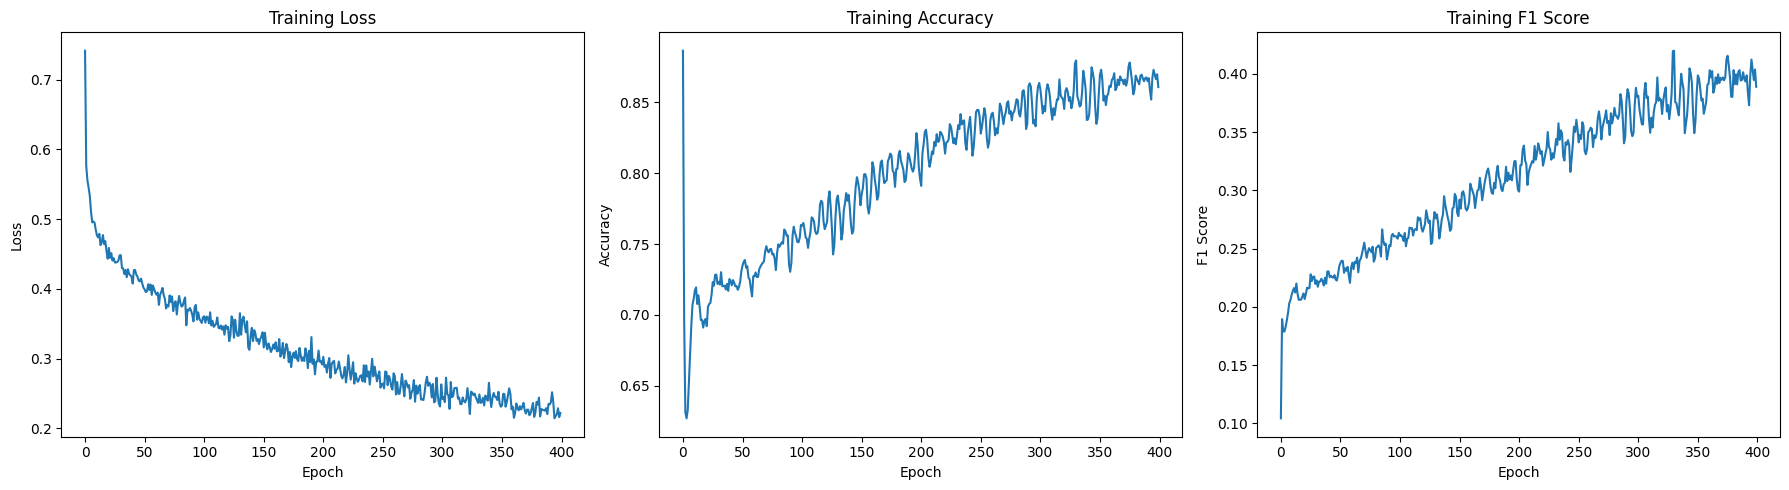

In [15]:
#================
# Training History Visualization
#================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training loss
axes[0].plot(history['train_loss'])
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

# Training accuracy
axes[1].plot(history['train_accuracy'])
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

# Training F1 score
axes[2].plot(history['train_f1'])
axes[2].set_title("Training F1 Score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")

plt.tight_layout()
plt.show()

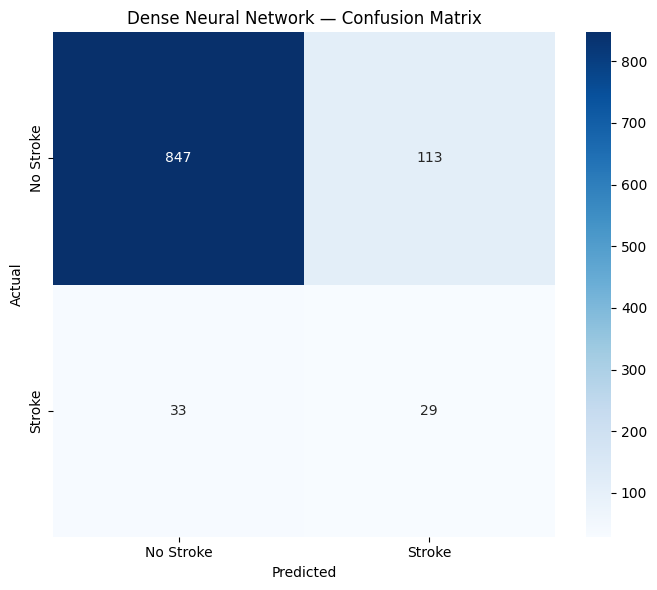

In [16]:
#================
# Confusion Matrix Visualization
#================

plt.figure(figsize=(7, 6))

sns.heatmap(
    metrics['confusion_matrix'],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Stroke', 'Stroke'],
    yticklabels=['No Stroke', 'Stroke']
)

plt.title("Dense Neural Network — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()